# Understanding Uncertainty and Accuracy in an Image Classifier

This notebook trains an image classifier that classifies **high-rise buildings** from **low-rise houses**. Following which an uncertainty analysis is taken to evaluate confidence and accuracy scores to understand:
1. Model behaviour and performance against different image categories
2. How to correctly interpret accuracy and confidence scores
3. The uncertainty range of model accuracy

**Why this matters:** Understanding accuracy and confidence in detail highlights the model's strengths and weaknesses. This helps users decide when to trust a prediction, and when to check it, before using the model in future applications.

**Steps**
1. Download training images
2. Train the model
3. Download, label and predict test images
4. Uncertainty analysis

Note: Results from Steps 1 to 3 may differ between runs, because Wikimedia Commons search results change over time and model training involves some randomness.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from fastai.vision.all import*
import os, time,requests
output_directory="/kaggle/working/building_classifier"
os.makedirs(output_directory, exist_ok=True)
custom_header={"User-Agent":"SM"}

## Step 1: Download training images

Images come from the Wikimedia Commons API.
- `fetch_image_urls` searches Commons and returns image links. It pages through results and skips duplicates.
- `download` saves each image into one folder per class, named `0000.jpg`, `0001.jpg` and so on.

In [ ]:
def fetch_image_urls(query,limit=50):
    wikimedia_api="https://commons.wikimedia.org//w/api.php"
    required_parameters={"action": "query",
                         "format":"json",
                         "generator":"search",
                         "gsrsearch": f"filetype:bitmap {query}",
                         "gsrnamespace":6,
                         "gsrlimit": min(limit,50),
                         "prop":"imageinfo",
                         "iiprop":"url|mime|extmetadata",
                         "iiurlwidth": 500}
    results=[]
    seen=set()
    # print(response)
    while len(results) < limit:
        print(len(results))
        response=requests.get(url=wikimedia_api,
                      params=required_parameters,headers=custom_header).json()
        if "error" in response:
            raise RuntimeError(response["error"])
        for page in response.get("query",{}).get("pages",{}).values():
            if "imageinfo" not in page or page["title"] in seen:
                continue
            seen.add(page["title"])
            info=page["imageinfo"][0]
            results.append({"title": page["title"],
                            "url": info.get("thumburl") or info["url"],
                            "license": info["extmetadata"].
                            get("LicenseShortName", {}).get("value")
            })
        if "continue" not in response:
             break                                  # no more results exist
        required_parameters.update(response["continue"])        # move to the next page
        time.sleep(0.5)
    return results             
    # print(results)

def download(archetype,selected_directory,items):
    for i, item in enumerate(items):
        # print(item["url"])
        # print(item["title"])
        file_name=item["url"].split("?")[0]or".jpg"
        ext=os.path.splitext(file_name)[1]
        # print(f"88888{output_directory}")
        class_dir=os.path.join(selected_directory,archetype)
        os.makedirs(class_dir, exist_ok=True)
        path=os.path.join(class_dir,f"{i:04d}{ext}")
        # print(path)
        get_image=requests.get(item["url"],headers=custom_header,timeout=60)
        if get_image.ok:
            with open(path,"wb") as f:
                f.write(get_image.content)
        else:
            print("failed, moving to next")
    print("download_complete")
        # print (ext)
        # print("it works")
        # break
   
        
        

Download and sort images as per building type 

In [ ]:
building_types=["buildings_high_rise","house_low_rise"]
for archetype in building_types:
    images=fetch_image_urls(archetype,limit=80)
    download(archetype,output_directory,images)
    

## Step 2: Train the model

- Remove broken image files.
- Build a fastai `DataBlock`: image in, category out, label taken from the folder name, 80/20 train/validation split, images resized to 224px, random augmentation.
- Fine-tune a pretrained ResNet34 for 2 epochs.

In [ ]:
#remove corrupt files
failed=verify_images(get_image_files(output_directory))
failed.map(Path.unlink)
print(f"Removed {len(failed)} bad images")

#build datablocks
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(),
)

#Build the actual data
dls = dblock.dataloaders(output_directory, bs=32)
print(dls.vocab)
print(len(dls.train_ds),len(dls.valid_ds))

#check datablock
dls.show_batch(max_n=9)
print(dls.vocab)
print(len(dls.train_ds),len(dls.valid_ds))

In [ ]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(2)

In [ ]:
# Evaluate on the validation set
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()
interp.plot_top_losses(3, nrows=3)   # shows the images it got most wrong


**Note:** The biggest error was a photo showing both low-rise houses (front) and high-rise buildings (behind). Mixed scenes like this have no single correct label.

## Step 3: Test the model

### 3.1 Download test images
Download new images from two searches, "low rise house" and "high rise buildings" (250 each), then check for duplicate files.

In [ ]:
#Gather data to test your model
image_test_directory="/kaggle/working/test_images"
category="houses and buildings"
low_rise_test_image_url=fetch_image_urls("low rise house",limit=250)
high_rise_test_image_url=fetch_image_urls("high rise buildings",limit=250)
test_image_url=low_rise_test_image_url+high_rise_test_image_url
test_images=download(category,image_test_directory,test_image_url)

In [ ]:
import hashlib
from collections import Counter

# a) Did the API return the same file more than once?
titles = [item["title"] for item in test_image_url]
print("URLs:", len(titles), "| unique titles:", len(set(titles)))

# b) Are identical image files on disk?
def file_hash(p):
    return hashlib.md5(open(p, "rb").read()).hexdigest()
    
path_for_test_files=os.path.join(image_test_directory,category)
files = get_image_files(path_for_test_files)
hashes = Counter(file_hash(f) for f in files)
print("Files:", len(files), "| unique contents:", len(hashes))

### 3.2 Label test images
Label each image by hand using the buttons: `low_rise_house`, `high_rise_buildings` or `other`.
`other` means neither class, such as interiors, maps or mixed scenes. Labels are saved to a CSV file.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

files = sorted(os.listdir(path_for_test_files))
labels = {}
state = {"i": 0}
out = widgets.Output()

def show():
    with out:
        clear_output(wait=True)
        if state["i"] >= len(files):
            print("Done:", len(labels), "labelled")
            return
        f = files[state["i"]]
        print(f"{state['i']+1}/{len(files)}: {f}")
        display(PILImage.create(os.path.join(path_for_test_files, f)).to_thumb(300))

def on_click(btn):
    labels[files[state["i"]]] = btn.description
    state["i"] += 1
    show()

buttons = [widgets.Button(description=d) for d in ["low_rise_house", "high_rise_buildings", "other"]]
for b in buttons:
    b.on_click(on_click)
display(widgets.HBox(buttons), out)
show()

In [ ]:
#save your data labels
pd.Series(labels, name="true").to_csv("/kaggle/working/test_labels.csv")

In [ ]:
label_df=pd.DataFrame.from_dict(labels,orient="index",columns=["correct_label"])
print(label_df)

### 3.3 Predict and save
Predict all test images in one batch. For each image, save:
- the predicted class
- the confidence (the highest probability)
- the probability for each class

Then join predictions and labels by file name and save the result for Step 4.

In [ ]:
# path_for_test_files=os.path.join(image_test_directory,category)
files = get_image_files(path_for_test_files)
test_dl = learn.dls.test_dl(files)
probs, _ = learn.get_preds(dl=test_dl)

record_df=pd.DataFrame({"file": [f.name for f in files],   "prediction": [learn.dls.vocab[i] for i in probs.argmax(1)],
    "confidence": probs.max(1).values.numpy() })

for i, c in enumerate(learn.dls.vocab):
    record_df[f"p_{c}"] = probs[:, i].numpy()

record_df.to_csv("/kaggle/working/predictions.csv", index=False)
record_df.head()

In [ ]:
#merge_the_two_dataframes
label_df.index=label_df.index.str.lower()
record_df["file"]=record_df["file"].str.lower()

merge_df=pd.merge(label_df,record_df,left_index=True,right_on="file",how="inner")
merge_df.head()
merge_df.to_csv("/kaggle/working/df_for_uncertainty.csv",index=False)


## Step 4: Uncertainty analysis

Two questions:
1. **How certain is the accuracy?**
2. **Does confidence match reality?** When the model says 90%, is it right 90% of the time?

Images labelled `other` are removed, leaving **391 images**.

In [23]:
#load your dataset with predictions and correct label
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score, brier_score_loss

full = pd.read_csv("/kaggle/input/datasets/shreenijmaharjan/r2-df-uncertainty/r2_df_uncertainty.csv",
                   index_col=0)                              # removes the "Unnamed: 0" column

# remove images labelled as other, as they are not part of this analysis
uc_input = full[full["correct_label"] != "other"].copy()
uc_input["result"]=uc_input.apply(lambda x: "correct" if x["prediction"]==x["correct_label"] else "incorrect", axis=1)
uc_input["is_correct"] = (uc_input["result"] == "correct").astype(int)
uc_input["y_high"] = (uc_input["correct_label"] == "high_rise_buildings").astype(int)

print(f"{len(uc_input)} images, accuracy {uc_input['is_correct'].mean():.1%}")
uc_input.head()

391 images, accuracy 86.7%


,correct_label,file,prediction,confidence,p_high_rise_buildings,p_low_rise_house,result,is_correct,y_high
0,high_rise_buildings,0000.jpg,low_rise_house,0.736403,0.263597,0.736403,incorrect,0,1
1,low_rise_house,0001.jpg,low_rise_house,0.993998,0.006002,0.993998,correct,1,0
2,low_rise_house,0002.jpg,low_rise_house,0.997201,0.002799,0.997201,correct,1,0
4,low_rise_house,0004.jpg,low_rise_house,0.968373,0.031627,0.968373,correct,1,0
5,low_rise_house,0005.jpg,high_rise_buildings,0.902213,0.902213,0.097787,incorrect,0,0


### 4.1 Results as usually reported


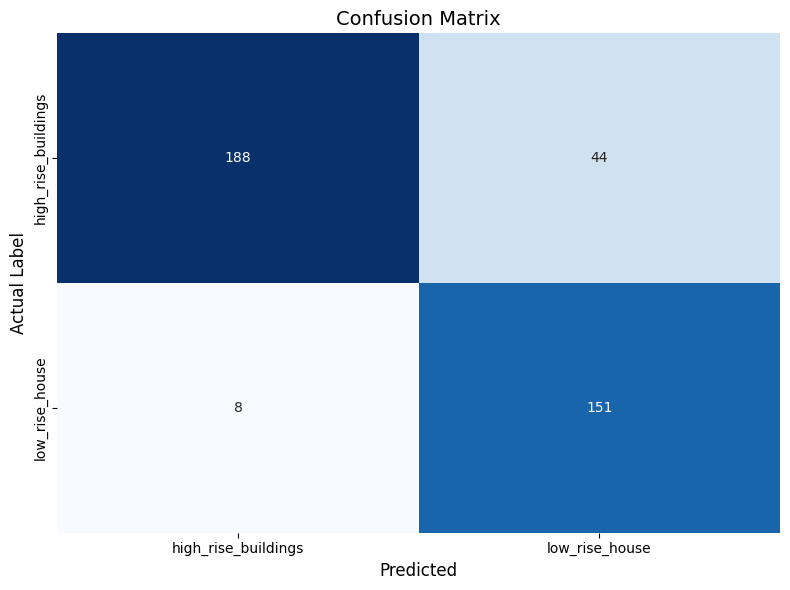

prediction           high_rise_buildings  low_rise_house
correct_label                                           
high_rise_buildings                  188              44
low_rise_house                         8             151


In [78]:
def confusion_matrix(df: pd.DataFrame,list_var:list):
    """ Input list_var=["correct_label", "prediction"]
    """
    cm_df=df.groupby(by=list_var)[list_var[0]].size().unstack(fill_value=0)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues",cbar=False)
    plt.title("Confusion Matrix", fontsize=14)
    plt.xlabel("Predicted", fontsize=12)
    plt.ylabel("Actual Label", fontsize=12)
    plt.tight_layout()
    plt.show()
    print(cm_df)
    return cm_df

list_var=["correct_label","prediction"]

cm_df=confusion_matrix(uc_input,list_var)


**Comments**
- 339 of 391 predictions are correct (**86.7%**).
- The errors are one-sided: **44 of 52** are high-rise buildings predicted as low-rise. Only 8 go the other way.

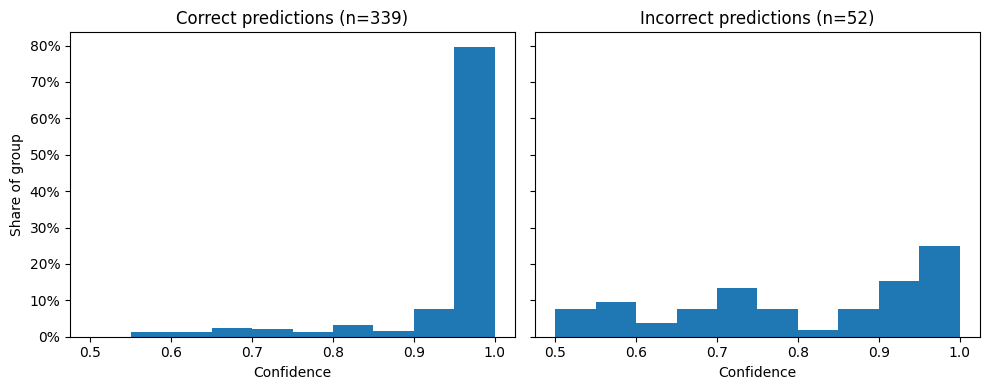

Confidence statistics
Correct: mean 0.957, median 0.997, variance 0.0082
Incorrect: mean 0.800, median 0.803, variance 0.0252
Errors made with confidence > 0.9: 40.4% (21 of 52)


In [24]:
c_group = uc_input[uc_input["result"] == "correct"]
ic_group = uc_input[uc_input["result"] == "incorrect"]

bins = np.linspace(0.5, 1.0, 11)            # same bins for both groups
fig, axs = plt.subplots(1, 2, tight_layout=True, sharey=True, figsize=(10, 4))
for ax, group, title in [(axs[0], c_group, "Correct predictions"),
                         (axs[1], ic_group, "Incorrect predictions")]:
    ax.hist(group["confidence"], bins=bins,
            weights=np.ones(len(group)) / len(group))   # each bar = share of that group
    ax.set_title(f"{title} (n={len(group)})")
    ax.set_xlabel("Confidence")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axs[0].set_ylabel("Share of group")
plt.show()

print("Confidence statistics")
for name, g in [("Correct", c_group), ("Incorrect", ic_group)]:
    print(f"{name}: mean {g['confidence'].mean():.3f}, median {g['confidence'].median():.3f}, "
          f"variance {g['confidence'].var():.4f}")
print(f"Errors made with confidence > 0.9: {(ic_group['confidence'] > 0.9).mean():.1%} "
      f"({(ic_group['confidence'] > 0.9).sum()} of {len(ic_group)})")

**Comments**
- Correct predictions are usually very confident (median 0.997).
- Wrong predictions are less confident (median 0.803) but spread widely.
- **21 of 52 errors (40%) were made with more than 90% confidence.** High confidence does not guarantee a correct answer.

### 4.2 How certain is the accuracy?
391 test images are one sample. A different set of images would give slightly different results.

**Bootstrap:** draw 391 images from the test set *with replacement*, recalculate each metric, and repeat 2,000 times. The middle 95% of the results is the **95% interval**.


             metric  estimate  ci_low  ci_high
0          Accuracy     0.867   0.834    0.900
1  High-rise recall     0.810   0.759    0.860
2   Low-rise recall     0.950   0.912    0.981


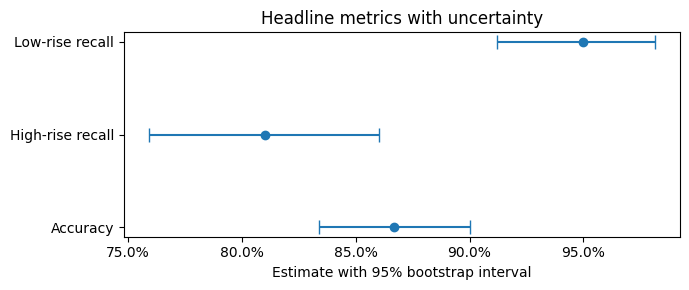

In [26]:
rng = np.random.default_rng(42)

def bootstrap_ci(data, stat, n_boot=2000):
    vals = [stat(data.sample(len(data), replace=True, random_state=rng.integers(1e9)))
            for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5])

metrics = {
    "Accuracy": lambda d: d["is_correct"].mean(),
    "High-rise recall": lambda d: d.loc[d["y_high"] == 1, "is_correct"].mean(),
    "Low-rise recall": lambda d: d.loc[d["y_high"] == 0, "is_correct"].mean(),
}

rows = []
for name, f in metrics.items():
    lo, hi = bootstrap_ci(uc_input, f)
    rows.append({"metric": name, "estimate": f(uc_input), "ci_low": lo, "ci_high": hi})
ci_table = pd.DataFrame(rows)
print(ci_table.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(ci_table["estimate"], ci_table["metric"],
            xerr=[ci_table["estimate"] - ci_table["ci_low"],
                  ci_table["ci_high"] - ci_table["estimate"]],
            fmt="o", capsize=5)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Estimate with 95% bootstrap interval")
ax.set_title("Headline metrics with uncertainty")
plt.tight_layout(); plt.show()

**Comments**

| Metric | Estimate | 95% interval |
|---|---|---|
| Accuracy | 86.7% | 83.4% to 90.0% |
| High-rise recall | 81.0% | 75.9% to 86.0% |
| Low-rise recall | 95.0% | 91.2% to 98.1% |

- Accuracy is best read as a range about 7 points wide, not a single number.
- The two recall intervals **do not overlap**, so the model really is worse at high-rise buildings.
- Recall intervals are wider than accuracy because each uses only one class's images.

### 4.3 Does 90% confidence mean 90% correct?
Predictions are grouped into 5 confidence bins (0.5 to 1.0). For each bin, average confidence is compared with actual accuracy.
- **Points below the dashed line** mean the model is overconfident.
- **ECE** is the average gap between confidence and accuracy, weighted by bin size (0 is perfect).
- **Brier score** is the average squared gap between the predicted probability and the true label (0 is perfect, 0.25 means always guessing 50%).

Results are also split by **predicted class**, since confidence is a claim about the predicted label.


All predictions
    mean_conf  accuracy    n
0      0.564     0.308   13
1      0.663     0.667   18
2      0.742     0.500   22
3      0.845     0.762   21
4      0.986     0.934  317

Predicted high-rise
    mean_conf  accuracy    n
0      0.563     0.600    5
1      0.662     0.909   11
2      0.741     0.800   10
3      0.838     1.000   12
4      0.982     0.981  158

Predicted low-rise
    mean_conf  accuracy    n
0      0.564     0.125    8
1      0.664     0.286    7
2      0.743     0.250   12
3      0.855     0.444    9
4      0.991     0.887  159


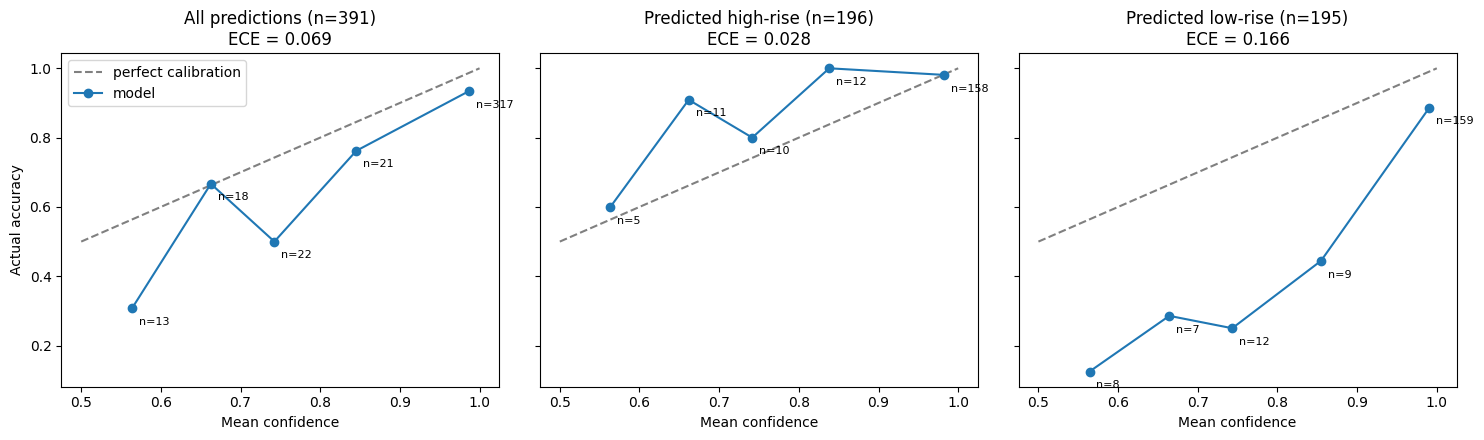


Brier score (all): 0.097


In [25]:
def reliability(conf, correct, n_bins=5):
    bins = np.linspace(0.5, 1.0, n_bins + 1)
    ids = np.clip(np.digitize(conf, bins) - 1, 0, n_bins - 1)
    rows = []
    for b in range(n_bins):
        m = ids == b
        if m.sum():
            rows.append((conf[m].mean(), correct[m].mean(), m.sum()))
    r = pd.DataFrame(rows, columns=["mean_conf", "accuracy", "n"])
    ece = (r["n"] / r["n"].sum() * (r["mean_conf"] - r["accuracy"]).abs()).sum()
    return r, ece

groups = {
    "All predictions": uc_input,
    "Predicted high-rise": uc_input[uc_input["prediction"] == "high_rise_buildings"],
    "Predicted low-rise": uc_input[uc_input["prediction"] == "low_rise_house"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (name, d) in zip(axes, groups.items()):
    table, ece = reliability(d["confidence"].values, d["is_correct"].values)
    ax.plot([0.5, 1], [0.5, 1], "--", color="grey", label="perfect calibration")
    ax.plot(table["mean_conf"], table["accuracy"], "o-", label="model")
    for _, r in table.iterrows():
        ax.annotate(f"n={int(r['n'])}", (r["mean_conf"], r["accuracy"]),
                    textcoords="offset points", xytext=(5, -12), fontsize=8)
    ax.set_title(f"{name} (n={len(d)})\nECE = {ece:.3f}")
    ax.set_xlabel("Mean confidence")
    print(f"\n{name}\n", table.round(3))
axes[0].set_ylabel("Actual accuracy")
axes[0].legend()
plt.tight_layout(); plt.show()

print(f"\nBrier score (all): {brier_score_loss(uc_input['y_high'], uc_input['p_high_rise_buildings']):.3f}")

**Comments**
- **Overall:** ECE 0.069, Brier 0.097. The model is slightly overconfident. Its top bin holds 317 predictions with 98.6% average confidence but 93.4% accuracy.
- **Predicted high-rise: well calibrated** (ECE about 0.03). Top bin: 98.2% confidence, 98.1% accuracy. Below 0.9 it is right *more* often than it claims.
- **Predicted low-rise: overconfident** (ECE about 0.17). Top bin: 99.1% confidence, only 88.7% accuracy. Below 0.9 confidence, it is right only **10 of 36 times (28%)**.
- The lower bins hold only 5 to 12 images each, so treat those points as rough.

## Conclusion
1. **Accuracy is a range.** 86.7% could plausibly be anywhere from 83% to 90%.
2. **The model is not equally good on both classes.** It misses high-rise buildings far more often than low-rise houses.
3. **Confidence cannot be taken at face value.** It is reliable for high-rise predictions but overconfident for low-rise predictions, the class that receives most of the errors.

**Practical rule:** trust high-rise predictions; review low-rise predictions below 0.9 confidence.

## Limitations
- Small training set (80 images per class) and only 2 epochs.
- Test images come from two searches and were labelled by one person.
- Low-confidence bins are small, and ECE depends on the number of bins (5 used here).
- Test images were not checked for overlap with training images.